# 4. Divergent series in practice

**Track:** advanced &nbsp;·&nbsp; **Prerequisites:** Chapters 1 and 3

Chapter 1 showed that a divergent series, stopped at its smallest term, can be very
accurate. This chapter asks two further questions. Why do the series of physics so
often diverge, and how fast? And can one do better than optimal truncation, using
the information hidden in the growth of the coefficients? The answers lead to
**Borel summation**, which can reconstruct a function from its divergent series,
and to **Padé approximants**, which often do the same with less effort. A final
section shows that the same tools accelerate slowly convergent series.

In [1]:
import math

import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np

try:
    import asymp as am
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import asymp as am

am.use_style()
mp.mp.dps = 100              # Padé approximants of high order need many digits

## 4.1 Why the series diverge

A small model, sometimes called zero-dimensional field theory, shows the mechanism.
Consider the integral

$$ Z(g) = \frac{1}{\sqrt{2\pi}}\int_{-\infty}^{\infty} e^{-x^2/2 - g x^4}\,\mathrm dx ,
   \qquad g \ge 0 , $$

the partition function of a single anharmonic degree of freedom, and the integral
behind the perturbation series of an anharmonic oscillator. Expanding
$e^{-gx^4}$ in powers of $g$ and integrating term by term with the Gaussian moments
$\langle x^{2m}\rangle = (2m)!/(2^m m!)$ gives

$$ Z(g) \sim \sum_{n=0}^\infty a_n g^n = 1 - 3g + \frac{105}{2}g^2 - \dots , \qquad
   a_n = (-1)^n \frac{(4n)!}{4^n\,(2n)!\,n!} . $$

The ratio of successive coefficients is $|a_{n+1}/a_n| \approx 16n$, so the
coefficients grow like $n!\,16^n$ and the series diverges for every $g > 0$.

Dyson's argument (1952) explains why it must. For $g < 0$ the integral does not
exist: the factor $e^{+|g|x^4}$ makes it diverge. A series that converged for
some $g > 0$ would converge in a disc around $g = 0$, including small negative
$g$, and define the function there. Since no function exists there, the series
cannot converge. The same reasoning applies whenever changing the sign of the
small parameter changes the physics qualitatively, as in quantum electrodynamics,
where it was first made. Factorially growing coefficients are the rule, not the
exception.

## 4.2 Optimal truncation: exponentially small errors

With coefficients growing like $n!\,A^{-n}$ (here $A = 1/16$), the terms
$n!\,(g/A)^n$ are smallest at $n \approx A/g$, and the error at optimal truncation
is of order $e^{-A/g}$, exponentially small, as found for Euler's series in
Chapter 1. Boyd (1999) calls this the **superasymptotic** approximation. The cell
computes $Z(g)$ by quadrature and compares.

In [2]:
def Z_exact(g):
    g = mp.mpf(g)
    return mp.quad(lambda x: mp.exp(-x**2 / 2 - g * x**4), [-mp.inf, 0, mp.inf]) / mp.sqrt(2 * mp.pi)


def coeff(n):
    return (-1) ** n * mp.factorial(4 * n) / (4**n * mp.factorial(2 * n) * mp.factorial(n))


coeffs = [coeff(n) for n in range(80)]
gs = np.array([0.004, 0.005, 0.006, 0.008, 0.01, 0.0125, 0.015, 0.02, 0.03, 0.05])
opt = []
for g in gs:
    exact = Z_exact(g)
    terms = [float(c * mp.mpf(g) ** n) for n, c in enumerate(coeffs)]
    tr = am.optimal_truncation(terms)
    opt.append((tr.n_terms, abs(tr.value - float(exact)), float(exact)))
    print(f"g = {g:6.4f}: Z = {float(exact):.10f};  keep {tr.n_terms:2d} terms, error {opt[-1][1]:.2e};"
          f"  sqrt(g) exp(-1/16g) = {math.sqrt(g) * math.exp(-1 / (16 * g)):.2e}")
opt_err = np.array([o[1] for o in opt])
slope = np.polyfit(1 / gs[gs <= 0.015], np.log(opt_err[gs <= 0.015] / np.sqrt(gs[gs <= 0.015])), 1)[0]
print(f"\nslope of ln(error / sqrt g) against 1/g: {slope:.4f}   (prediction -1/16 = {-1 / 16:.4f})")

g = 0.0040: Z = 0.9887464686;  keep 16 terms, error 1.16e-08;  sqrt(g) exp(-1/16g) = 1.04e-08


g = 0.0050: Z = 0.9861363814;  keep 13 terms, error 2.92e-07;  sqrt(g) exp(-1/16g) = 2.64e-07
g = 0.0060: Z = 0.9835960676;  keep 11 terms, error 2.55e-06;  sqrt(g) exp(-1/16g) = 2.32e-06


g = 0.0080: Z = 0.9787070560;  keep  8 terms, error 4.06e-05;  sqrt(g) exp(-1/16g) = 3.62e-05
g = 0.0100: Z = 0.9740486071;  keep  7 terms, error 2.07e-04;  sqrt(g) exp(-1/16g) = 1.93e-04


g = 0.0125: Z = 0.9685121885;  keep  5 terms, error 8.69e-04;  sqrt(g) exp(-1/16g) = 7.53e-04
g = 0.0150: Z = 0.9632578648;  keep  5 terms, error 1.98e-03;  sqrt(g) exp(-1/16g) = 1.90e-03


g = 0.0200: Z = 0.9534737956;  keep  4 terms, error 6.33e-03;  sqrt(g) exp(-1/16g) = 6.21e-03
g = 0.0300: Z = 0.9362030081;  keep  3 terms, error 2.10e-02;  sqrt(g) exp(-1/16g) = 2.16e-02


g = 0.0500: Z = 0.9079847774;  keep  2 terms, error 5.80e-02;  sqrt(g) exp(-1/16g) = 6.41e-02

slope of ln(error / sqrt g) against 1/g: -0.0624   (prediction -1/16 = -0.0625)


The error of the optimally truncated series follows $\sqrt g\,e^{-1/(16g)}$ closely
(the prefactor is an observation here, not a derivation), and the measured
exponent agrees with $-1/16$ to three digits. For $g = 0.005$ the series gives
about six correct digits. But at $g = 0.05$, a coupling that is still
"small", the best it can do is 6 %, using only two terms: the factorial growth
takes over almost at once. Optimal truncation is a fixed limit for each $g$, and
better accuracy needs another idea.

## 4.3 Borel summation

The trouble is the factor $n!$ in the coefficients. Borel's idea is to remove it
and put it back as an integral, using $n! = \int_0^\infty t^n e^{-t}\,\mathrm dt$.
Define the **Borel transform**

$$ B(t) = \sum_{n=0}^{\infty} \frac{a_n}{n!}\,t^n . $$

Its coefficients grow only like $16^n$, so it converges in a disc $|t| < 1/16$.
Formally exchanging sum and integral,

$$ \sum_n a_n g^n = \sum_n \frac{a_n}{n!}\,g^n\int_0^\infty t^n e^{-t}\,\mathrm dt
   \;\to\; \int_0^\infty e^{-t}\,B(gt)\,\mathrm dt , $$

which defines the **Borel sum**. It is finite if $B$ can be continued along the
positive real axis and does not grow too fast. For Euler's series of Chapter 1,
$B(t) = 1/(1 + t)$ exactly, and the Borel sum reproduces $E(x)$. For $Z(g)$ the
singularity of $B$ lies at $t = -1/16$, on the *negative* axis, so the integration
path is free and the series is Borel summable. Theorems of Watson and Sokal (1980)
state when the Borel sum equals the original function.

In practice only finitely many coefficients are known. The **Borel–Padé** method
continues $B(t)$ beyond its disc of convergence by a Padé approximant: a ratio
of polynomials $P_M(t)/Q_M(t)$ whose Taylor series matches the first $2M + 1$
coefficients of $B$. Rational functions can represent
singularities, which polynomials cannot. The cell computes Borel–Padé sums, and
for comparison diagonal Padé approximants of the original series, at $g = 0.05$,
where optimal truncation gave 6 %.

In [3]:
def pade_coeffs(c, M):
    p, q = mp.pade(c[: 2 * M + 1], M, M)
    return p, q


def ratfun(p, q, t):
    return mp.polyval(p[::-1], t) / mp.polyval(q[::-1], t)


g_bp = mp.mpf("0.05")
Z_bp = Z_exact(g_bp)
Ms = [1, 2, 3, 4, 6, 8, 10, 12, 14, 16, 18]
err_bp, err_pade = [], []
borel_coeffs = [c / mp.factorial(n) for n, c in enumerate(coeffs)]
for M in Ms:
    p, q = pade_coeffs(borel_coeffs, M)
    bp = mp.quad(lambda t: mp.exp(-t) * ratfun(p, q, g_bp * t), [0, mp.inf])
    p2, q2 = pade_coeffs(coeffs, M)
    err_bp.append(float(abs(bp - Z_bp)))
    err_pade.append(float(abs(ratfun(p2, q2, g_bp) - Z_bp)))
    print(f"{2 * M + 1:2d} coefficients:  Borel-Padé error {err_bp[-1]:.1e};  Padé [{M}/{M}] error {err_pade[-1]:.1e}")
print(f"optimal truncation at g = 0.05: error {opt_err[gs == 0.05][0]:.1e}")

 3 coefficients:  Borel-Padé error 4.5e-03;  Padé [1/1] error 1.2e-02
 5 coefficients:  Borel-Padé error 3.5e-04;  Padé [2/2] error 2.7e-03
 7 coefficients:  Borel-Padé error 3.7e-05;  Padé [3/3] error 7.6e-04


 9 coefficients:  Borel-Padé error 4.6e-06;  Padé [4/4] error 2.5e-04
13 coefficients:  Borel-Padé error 1.1e-07;  Padé [6/6] error 3.8e-05


17 coefficients:  Borel-Padé error 3.4e-09;  Padé [8/8] error 7.6e-06
21 coefficients:  Borel-Padé error 1.4e-10;  Padé [10/10] error 1.8e-06


25 coefficients:  Borel-Padé error 7.2e-12;  Padé [12/12] error 4.9e-07


29 coefficients:  Borel-Padé error 4.2e-13;  Padé [14/14] error 1.5e-07


33 coefficients:  Borel-Padé error 2.8e-14;  Padé [16/16] error 4.7e-08


37 coefficients:  Borel-Padé error 2.1e-15;  Padé [18/18] error 1.6e-08
optimal truncation at g = 0.05: error 5.8e-02


With the same 29 coefficients that the truncated series cannot use (it stops at
two), Borel–Padé gives $Z(0.05)$ to twelve or thirteen digits, and its error keeps
falling as coefficients are added. Even the diagonal Padé approximants of the
divergent series itself converge, more slowly. Both succeed because they use what
the series knows about the location of the singularity, through the growth of
its coefficients. Their success is not guaranteed in general; it is a property of
series of Stieltjes type, such as $E(x)$ and $Z(g)$,
and it should always be checked, as here, against an independent calculation.

## 4.4 Accelerating slowly convergent series

The same tools help with series that converge, but slowly. Leibniz's series

$$ \frac{\pi}{4} = 1 - \frac13 + \frac15 - \frac17 + \dots $$

needs about $10^n$ terms for $n$ digits. Its partial sums oscillate about the limit
with an error that alternates in sign and decreases slowly. The **Shanks
transformation** (`am.shanks`) fits each three consecutive partial sums with the
form $S + \beta q^n$ and returns $S$; it is exact for a geometric error and very
effective for an alternating one. It can be applied repeatedly.

In [4]:
N_leib = 30
S = am.partial_sums([(-1) ** k / (2 * k + 1) for k in range(N_leib)])
shanks_seq = [S]
for _ in range(4):
    shanks_seq.append(am.shanks(shanks_seq[-1]))
for k, seq in enumerate(shanks_seq):
    print(f"Shanks applied {k} times: last value {seq[-1]:.15f}, error {abs(seq[-1] - math.pi / 4):.1e}"
          f"  (from {N_leib} terms)")

Shanks applied 0 times: last value 0.777067141674737, error 8.3e-03  (from 30 terms)
Shanks applied 1 times: last value 0.785395604561935, error 2.6e-06  (from 30 terms)
Shanks applied 2 times: last value 0.785398160687941, error 2.7e-09  (from 30 terms)
Shanks applied 3 times: last value 0.785398158055007, error 5.3e-09  (from 30 terms)
Shanks applied 4 times: last value 0.785398241030594, error 7.8e-08  (from 30 terms)


Thirty terms of the series give two digits. One Shanks transformation of the same
thirty partial sums gives five or six, and a second gives eight or nine. A third
and fourth make the result *worse*: each transformation divides by differences of
nearly equal numbers, and in double precision the rounding error, amplified at each
step, takes over. It is the cancellation of Section 1.4 again, and the remedy is
the same: stop early, or work with more digits. Shanks' transformation is
equivalent to a Padé approximant of the series, so this
is the same idea as Section 4.3: a few parameters of a rational function capture
what many terms only approximate.

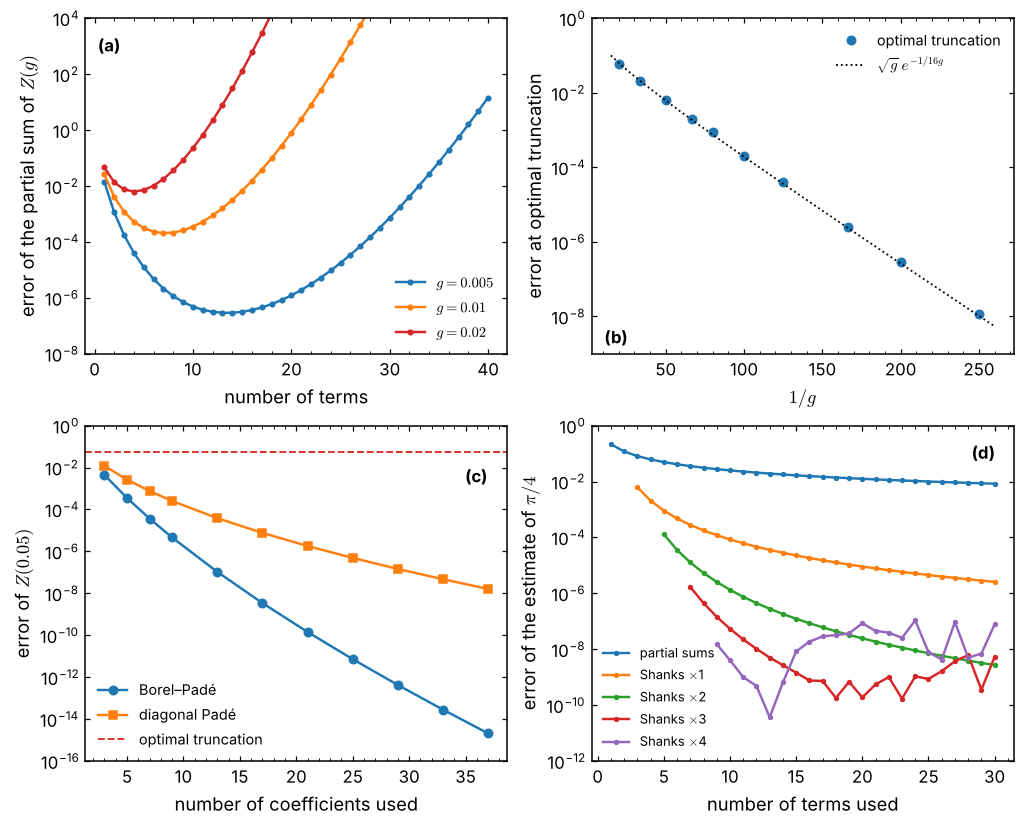

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
for g, c in ((0.005, "C0"), (0.01, "C1"), (0.02, "C3")):
    exact = float(Z_exact(g))
    n = np.arange(1, 41)
    terms = np.array([float(cn * mp.mpf(g) ** k) for k, cn in enumerate(coeffs[:40])])
    ax.semilogy(n, np.abs(np.cumsum(terms) - exact), "o-", ms=3, color=c, label=f"$g = {g}$")
ax.set_xlabel("number of terms"); ax.set_ylabel(r"error of the partial sum of $Z(g)$")
ax.set_ylim(1e-8, 1e4); ax.legend(loc="lower right"); am.panel_label(ax, "(a)")

ax = axes[0, 1]
ax.semilogy(1 / gs, opt_err, "o", color="C0", label="optimal truncation")
inv = np.linspace(15, 260, 200)
ax.semilogy(inv, np.sqrt(1 / inv) * np.exp(-inv / 16), "k:", lw=1.2, label=r"$\sqrt{g}\,e^{-1/16g}$")
ax.set_xlabel("$1/g$"); ax.set_ylabel("error at optimal truncation")
ax.set_ylim(1e-9, 1); ax.legend(loc="upper right"); am.panel_label(ax, "(b)", y=0.08)

ax = axes[1, 0]
nc = [2 * M + 1 for M in Ms]
ax.semilogy(nc, err_bp, "o-", color="C0", label="Borel–Padé")
ax.semilogy(nc, err_pade, "s-", color="C1", label="diagonal Padé")
ax.axhline(opt_err[gs == 0.05][0], color="C3", ls="--", lw=1.2, label="optimal truncation")
ax.set_xlabel("number of coefficients used"); ax.set_ylabel(r"error of $Z(0.05)$")
ax.set_ylim(1e-16, 1); ax.legend(loc="lower left"); am.panel_label(ax, "(c)", x=0.9, y=0.88)

ax = axes[1, 1]
for k, (seq, c) in enumerate(zip(shanks_seq, ("C0", "C1", "C2", "C3", "C4"))):
    ax.semilogy(np.arange(seq.size) + 1 + 2 * k, np.abs(seq - math.pi / 4) + 1e-17, "o-", ms=2.5, color=c,
                label="partial sums" if k == 0 else f"Shanks $\\times${k}")
ax.set_xlabel("number of terms used"); ax.set_ylabel(r"error of the estimate of $\pi/4$")
ax.set_ylim(1e-12, 1); ax.legend(loc="lower left", fontsize=8.5); am.panel_label(ax, "(d)", x=0.9)
plt.show()

**(a)** Error of the partial sums of the series for $Z(g)$ against the number of
terms. **(b)** Error at optimal truncation against $1/g$, with the observed form
$\sqrt g\,e^{-1/16g}$. **(c)** Borel–Padé sums and diagonal Padé approximants at
$g = 0.05$, against the number of coefficients; dashed: the best that truncation
can do. **(d)** Repeated Shanks transformations of Leibniz's series for $\pi/4$, in
double precision; after two, rounding error dominates.

## Summary

* The series of physics usually diverge because their coefficients grow
  factorially, often for a physical reason (Dyson's argument).
* With coefficients growing like $n!\,A^{-n}$, optimal truncation gives an error of
  order $e^{-A/\varepsilon}$, exponentially small but fixed for each $\varepsilon$.
* Borel summation removes the factorial and restores it as an integral; with a
  Padé continuation of the Borel transform it can go far beyond optimal truncation.
* Padé approximants and Shanks transformations sum divergent series of Stieltjes
  type and accelerate slowly convergent ones. They amplify rounding error, and
  their success must always be checked.

## Suggested references

* G. A. Baker and P. Graves-Morris, *Padé Approximants*, 2nd ed. (Cambridge
  University Press, 1996).
* C. M. Bender and S. A. Orszag, *Advanced Mathematical Methods for Scientists
  and Engineers* (McGraw-Hill, 1978; Springer, 1999).
* J. P. Boyd, "The devil's invention: asymptotic, superasymptotic and
  hyperasymptotic series", *Acta Appl. Math.* **56**, 1 (1999).
* F. J. Dyson, "Divergence of perturbation theory in quantum electrodynamics",
  *Phys. Rev.* **85**, 631 (1952).
* E. J. Hinch, *Perturbation Methods* (Cambridge University Press, 1991).
* A. D. Sokal, "An improvement of Watson's theorem on Borel summability",
  *J. Math. Phys.* **21**, 261 (1980).

## Exercises

1. Show that the ratio of successive coefficients of the series for $Z(g)$ is
   $(4n+1)(4n+2)(4n+3)/(2(2n+1)(n+1))$ in magnitude, and hence about $16n$.
2. Compute the Borel transform of Euler's series and show that its Borel sum is
   $E(x)$ exactly.
3. Repeat Section 4.3 for $g = 0.2$ and $g = 1$. How many coefficients does
   Borel–Padé need for six digits?
4. Apply the Shanks transformation to the partial sums of $\sum 1/n^2$. Why does
   it help much less than for Leibniz's series?

---

**Previous:** [3. Order symbols, gauge functions and uniqueness](03_order_symbols_and_gauge_functions.ipynb) &nbsp;·&nbsp; **Next:** [5. Integration by parts and Watson's lemma](../part2_integrals_and_sums/05_integration_by_parts_and_watsons_lemma.ipynb)